# EDA Bitcoin Alpha

## Pergunta de pesquisa
Como padrões de confiança e desconfiança influenciam a conectividade, a formação de caminhos e os ciclos de avaliações negativas na rede Bitcoin Alpha?

Cada linha é uma avaliação direcionada entre usuários. O sinal da nota representa confiança ou desconfiança.

Fonte: [SNAP — Bitcoin Alpha](https://snap.stanford.edu/data/soc-sign-bitcoin-alpha.html). Base utilizada: CSV da versão 4 do projeto.

## Setup de bibliotecas e dados
Execute na raiz do projeto ou mantenha o CSV ao lado do notebook. Dependências: pandas, numpy, matplotlib, seaborn e scipy.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
sns.set_theme(style="whitegrid")
POSITIVA, NEGATIVA = "#3A9D75", "#D96C60"
cores = {"Positiva": POSITIVA, "Negativa": NEGATIVA}
candidatos = [Path("data/dataset_parte2/soc-sign-bitcoinalpha.csv"), Path("soc-sign-bitcoinalpha.csv"), Path("soc-sign-bitcoinalpha.csv.gz")]
caminho = next((p for p in candidatos if p.exists()), None)
if caminho is None:
    raise FileNotFoundError("Coloque o CSV do Bitcoin Alpha ao lado do notebook.")
df = pd.read_csv(caminho, header=None, names=["origem", "destino", "nota", "timestamp"])
df.head()

,origem,destino,nota,timestamp
0,7188,1,10,1407470400
1,430,1,10,1376539200
2,3134,1,10,1369713600
3,3026,1,10,1350014400
4,3010,1,10,1347854400


## 1. Princípio estrutural
**Pergunta:** qual é a dimensão da rede e o significado das variáveis? IDs são identificadores, não medidas quantitativas.

In [2]:
print("Dimensão:", df.shape)
df.info()
print("Duplicadas completas:", df.duplicated().sum())
print("Pares origem-destino repetidos:", df.duplicated(["origem", "destino"]).sum())
usuarios = pd.Index(sorted(set(df.origem) | set(df.destino)))
print("Usuários:", len(usuarios))
print("Notas inválidas:", (~df.nota.between(-10,10) | df.nota.eq(0)).sum())

Dimensão: (24186, 4)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24186 entries, 0 to 24185
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   origem     24186 non-null  int64
 1   destino    24186 non-null  int64
 2   nota       24186 non-null  int64
 3   timestamp  24186 non-null  int64
dtypes: int64(4)
memory usage: 755.9 KB
Duplicadas completas: 0
Pares origem-destino repetidos: 0
Usuários: 3783
Notas inválidas: 0


**Discussão:** são 24.186 registros e 3.783 usuários distintos. Origem e destino representam os extremos de um arco; nota é seu peso e timestamp registra o instante da avaliação. Não há duplicatas completas.

## 2. Dados faltantes
**Pergunta:** existem valores ausentes que exigem imputação?

In [3]:
df.isna().sum()

origem       0
destino      0
nota         0
timestamp    0
dtype: int64

Não há valores ausentes nas quatro colunas. Não se aplica imputação nem classificação de mecanismo MCAR/MAR/MNAR. A ausência de um arco não equivale a um dado faltante em uma linha.

In [ ]:
df["data"] = pd.to_datetime(df.timestamp, unit="s", utc=True)
df["ano"] = df.data.dt.year
df["negativa"] = df.nota.lt(0)
df["tipo"] = np.where(df.negativa, "Negativa", "Positiva")
print(df.data.min(), df.data.max())
por_usuario = pd.DataFrame(index=usuarios)
por_usuario["enviadas"] = df.groupby("origem").size().reindex(usuarios, fill_value=0)
por_usuario["recebidas"] = df.groupby("destino").size().reindex(usuarios, fill_value=0)
por_usuario["negativas_recebidas"] = df.groupby("destino").negativa.sum().reindex(usuarios, fill_value=0)
por_usuario["saldo_+/-"] = df.groupby("destino").nota.sum().reindex(usuarios, fill_value=0)
por_usuario.head()

2010-11-08 05:00:00+00:00 2016-01-22 05:00:00+00:00


,enviadas,recebidas,negativas_recebidas,saldo_recebido
1,490,398,0,758
2,195,205,0,735
3,243,251,1,610
4,215,201,0,588
5,174,146,1,390


## 3. Princípio distribucional
**Pergunta:** como as notas e a atividade dos usuários se distribuem?

In [5]:
def descritiva(dados):
    tabela = dados.describe().T
    tabela["assimetria"] = dados.skew()
    tabela["curtose"] = dados.kurt()
    return tabela
antes = descritiva(df[["nota"]])
display(antes.round(3), descritiva(por_usuario).round(3))

,count,mean,std,min,25%,50%,75%,max,assimetria,curtose
nota,24186.0,1.464,2.904,-10.0,1.0,1.0,2.0,10.0,-1.346,7.643


,count,mean,std,min,25%,50%,75%,max,assimetria,curtose
enviadas,3783.0,6.393,18.295,0.0,1.0,2.0,5.0,490.0,10.446,179.282
recebidas,3783.0,6.393,16.407,0.0,1.0,2.0,5.0,398.0,9.306,138.334
negativas_recebidas,3783.0,0.406,2.045,0.0,0.0,0.0,0.0,69.0,17.231,443.906
saldo_recebido,3783.0,9.360,36.940,-628.0,1.0,3.0,8.0,758.0,7.548,159.201


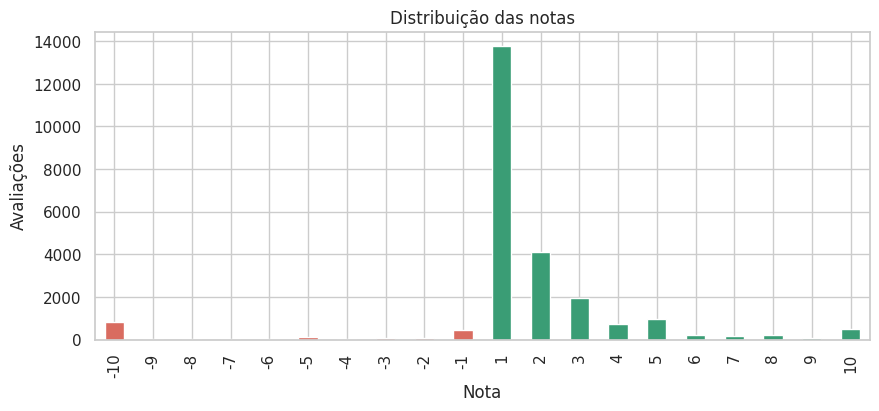

In [6]:
contagem = df.nota.value_counts().sort_index()
contagem.plot.bar(color=[NEGATIVA if x < 0 else POSITIVA for x in contagem.index], figsize=(10,4))
plt.title("Distribuição das notas"); plt.xlabel("Nota"); plt.ylabel("Avaliações"); plt.show()

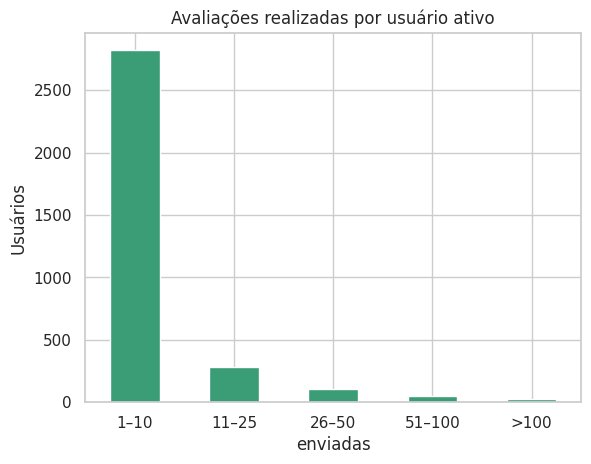

In [7]:
atividade = por_usuario.loc[por_usuario.enviadas.gt(0), "enviadas"]
faixas = pd.cut(atividade, [0,10,25,50,100,np.inf], labels=["1–10","11–25","26–50","51–100",">100"])
faixas.value_counts(sort=False).plot.bar(color=POSITIVA)
plt.title("Avaliações realizadas por usuário ativo"); plt.ylabel("Usuários"); plt.xticks(rotation=0); plt.show()

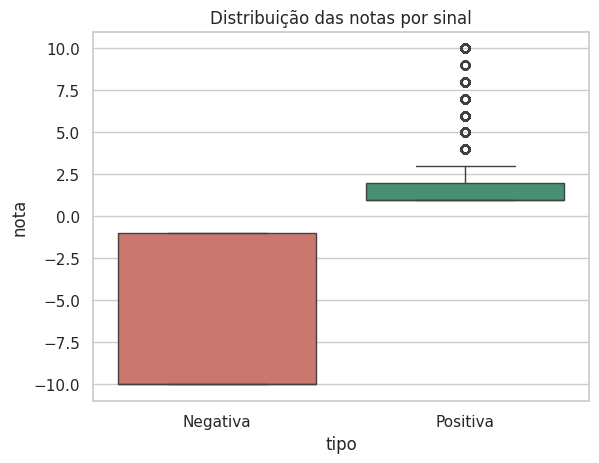

,count,mean,std,min,25%,50%,75%,max
tipo,,,,,,,,
Negativa,1536.0,-6.38,4.08,-10.0,-10.0,-10.0,-1.0,-1.0
Positiva,22650.0,2.00,1.85,1.0,1.0,1.0,2.0,10.0


In [8]:
sns.boxplot(data=df, x="tipo", y="nota", order=["Negativa","Positiva"], hue="tipo", palette=cores, dodge=False)
plt.title("Distribuição das notas por sinal"); plt.show()
display(df.groupby("tipo").nota.describe().round(2))

**Discussão:** as notas positivas predominam e se concentram em valores baixos, enquanto as negativas incluem muitas notas -10. A maioria dos usuários que avaliam realiza poucas avaliações. A nota é discreta e limitada, não uma variável normalmente distribuída.

Shapiro-Wilk (amostra): W=0.6599, p=4.88e-72


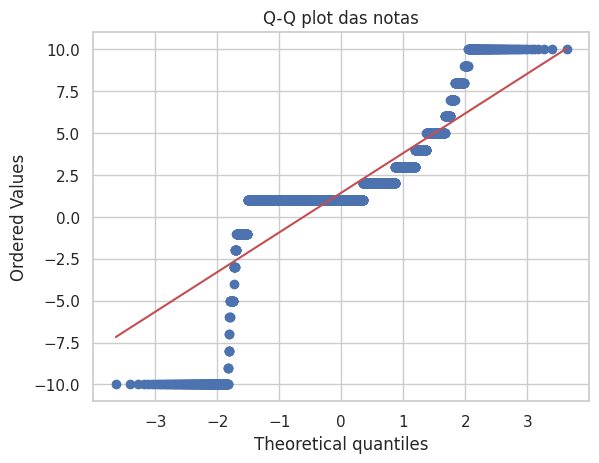

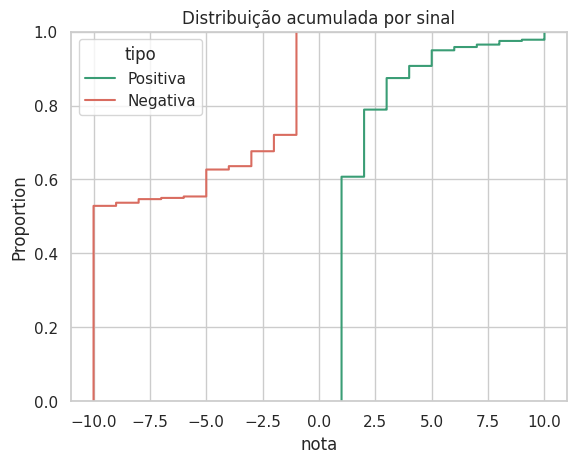

In [9]:
amostra = df.nota.sample(min(5000,len(df)), random_state=42)
w,p = stats.shapiro(amostra)
print(f"Shapiro-Wilk (amostra): W={w:.4f}, p={p:.3g}")
stats.probplot(amostra, dist="norm", plot=plt); plt.title("Q-Q plot das notas"); plt.show()
sns.ecdfplot(data=df, x="nota", hue="tipo", palette=cores); plt.title("Distribuição acumulada por sinal"); plt.show()

O teste de normalidade é apenas diagnóstico: as avaliações podem ser dependentes por compartilharem usuários. A distribuição discreta e limitada já desaconselha pressupor normalidade.

## 4. Tratamento de dados ausentes e outliers
**Pergunta:** valores extremos são erros ou características reais da rede?

Limites IQR: -0.5 3.5
Notas sinalizadas: 4380


nota
-10    812
-9      13
-8      15
-7       5
-6       6
-5     112
-4      14
-3      62
-2      68
-1     429
 4     744
 5     957
 6     201
 7     149
 8     224
 9      75
 10    494
Name: count, dtype: int64

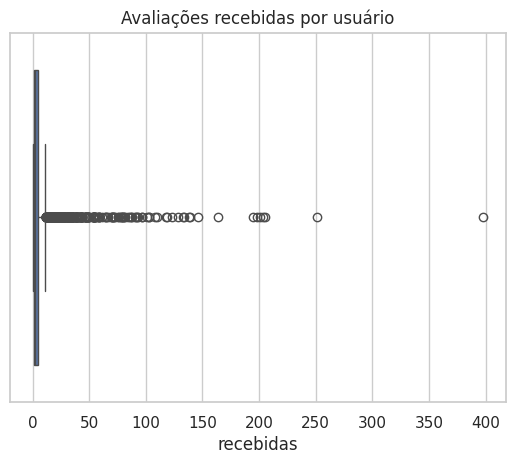

In [10]:
q1, q3 = df.nota.quantile([.25,.75])
iqr = q3-q1
lim_inf, lim_sup = q1-1.5*iqr, q3+1.5*iqr
outliers = df.loc[~df.nota.between(lim_inf,lim_sup)]
print("Limites IQR:", lim_inf, lim_sup)
print("Notas sinalizadas:", len(outliers))
display(outliers.nota.value_counts().sort_index())
sns.boxplot(x=por_usuario.recebidas); plt.title("Avaliações recebidas por usuário"); plt.show()

Notas extremas dentro da escala válida e usuários muito ativos são informações relevantes, não erros comprovados. Não removemos nem imputamos registros. Uma escala logarítmica pode ajudar a visualizar graus, sem alterar o grafo original.

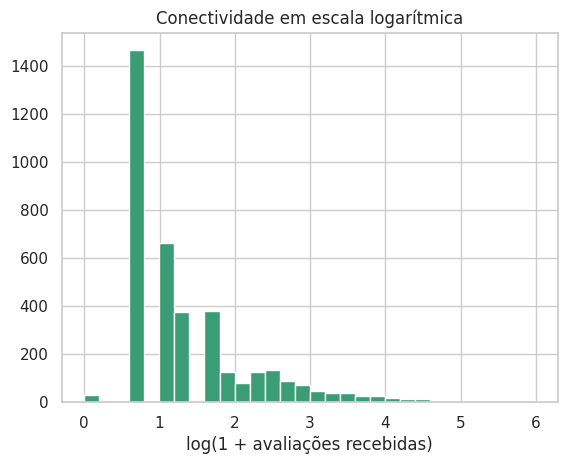

In [11]:
plt.hist(np.log1p(por_usuario.recebidas), bins=30, color=POSITIVA)
plt.xlabel("log(1 + avaliações recebidas)"); plt.title("Conectividade em escala logarítmica"); plt.show()
df_tratado = df.copy()

## 5. Estatística descritiva — antes e depois

In [12]:
depois = descritiva(df_tratado[["nota"]])
display(pd.concat({"Antes": antes, "Depois": depois, "Diferença": depois-antes}).round(3))
assert df_tratado.equals(df)

,,count,mean,std,min,25%,50%,75%,max,assimetria,curtose
Antes,nota,24186.0,1.464,2.904,-10.0,1.0,1.0,2.0,10.0,-1.346,7.643
Depois,nota,24186.0,1.464,2.904,-10.0,1.0,1.0,2.0,10.0,-1.346,7.643
Diferença,nota,0.0,0.000,0.000,0.0,0.0,0.0,0.0,0.0,0.000,0.000


A diferença é zero porque não havia justificativa para modificar as observações. As variáveis derivadas preservam os registros originais.

## 6. Princípio relacional
### Frequências e desbalanceamento
**Pergunta:** qual sinal predomina?

In [13]:
freq = df.tipo.value_counts()
display(pd.DataFrame({"Quantidade":freq,"Percentual":100*freq/len(df)}).round(2))
print("Entropia normalizada:", stats.entropy(freq, base=2))

,Quantidade,Percentual
tipo,,
Positiva,22650,93.65
Negativa,1536,6.35


Entropia normalizada: 0.34121504543685016


A confiança predomina: 22.650 avaliações positivas e 1.536 negativas. O desbalanceamento é uma característica observada da rede, não motivo para reamostrar a EDA.

### Evolução temporal
**Pergunta:** como o volume de avaliações muda ao longo do tempo?

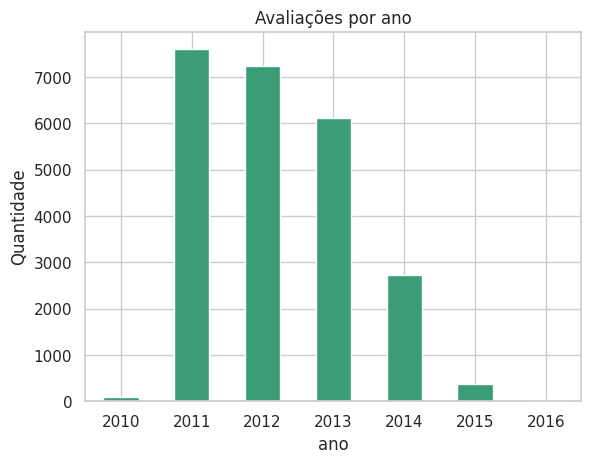

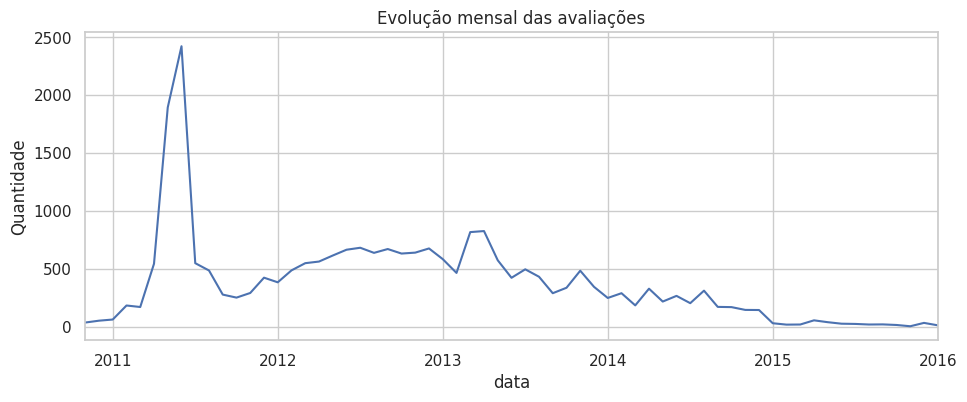

In [14]:
df.groupby("ano").size().plot.bar(color=POSITIVA)
plt.title("Avaliações por ano"); plt.ylabel("Quantidade"); plt.xticks(rotation=0); plt.show()
df.set_index("data").resample("MS").size().plot(figsize=(11,4))
plt.title("Evolução mensal das avaliações"); plt.ylabel("Quantidade"); plt.show()

O volume é maior em 2011 e diminui nos anos seguintes. Os anos extremos têm cobertura parcial. Volume absoluto e proporção de negativas respondem a perguntas diferentes.

### Análise bivariada e multivariada
**Pergunta:** usuários mais avaliados recebem mais negativas?

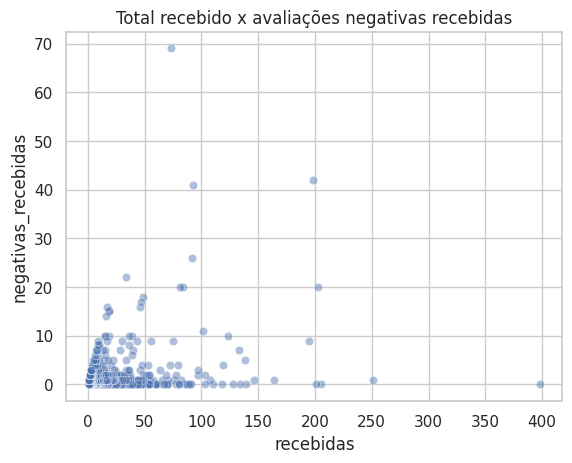

,enviadas,recebidas,negativas_recebidas,saldo_recebido
enviadas,1.000,0.971,0.271,0.824
recebidas,0.971,1.000,0.349,0.816
negativas_recebidas,0.271,0.349,1.000,-0.193
saldo_recebido,0.824,0.816,-0.193,1.000


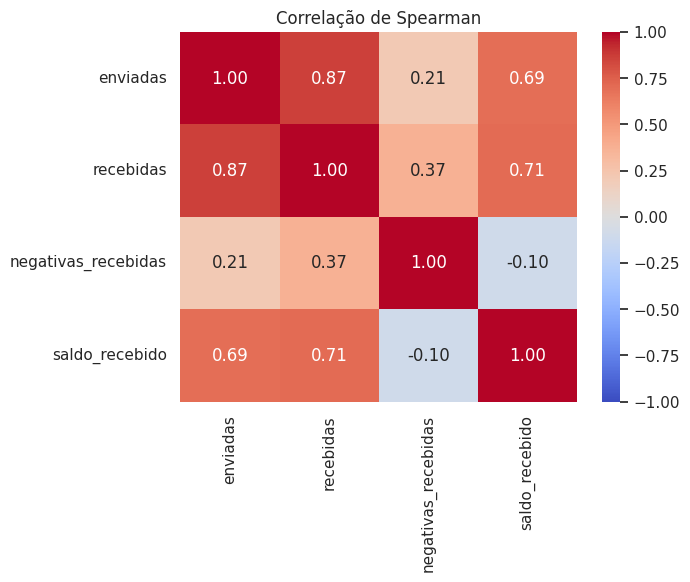

In [15]:
recebedores = por_usuario.loc[por_usuario.recebidas.gt(0)].copy()
sns.scatterplot(data=recebedores, x="recebidas", y="negativas_recebidas", alpha=.45)
plt.title("Total recebido x avaliações negativas recebidas"); plt.show()
variaveis = ["enviadas", "recebidas", "negativas_recebidas", "saldo_recebido"]
display(recebedores[variaveis].corr(method="pearson").round(3))
sns.heatmap(recebedores[variaveis].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1,vmax=1)
plt.title("Correlação de Spearman"); plt.show()

A dispersão permite identificar usuários muito avaliados com poucas negativas e outros com muitas negativas. O número de negativas é parte do total recebido; a correlação não é evidência independente de causalidade. IDs e timestamps brutos não entram na matriz. Não há atributos demográficos para avaliar fairness entre grupos protegidos.

## 7. Visualizações explanatórias e storytelling
### Proporção de confiança e desconfiança por ano

tipo,Positiva,Negativa,Total,Positiva (%),Negativa (%)
ano,,,,,
2010,98,0,98,100.00,0.00
2011,7455,148,7603,98.05,1.95
2012,6871,379,7250,94.77,5.23
2013,5571,550,6121,91.01,8.99
2014,2318,417,2735,84.75,15.25
2015,321,41,362,88.67,11.33
2016,16,1,17,94.12,5.88


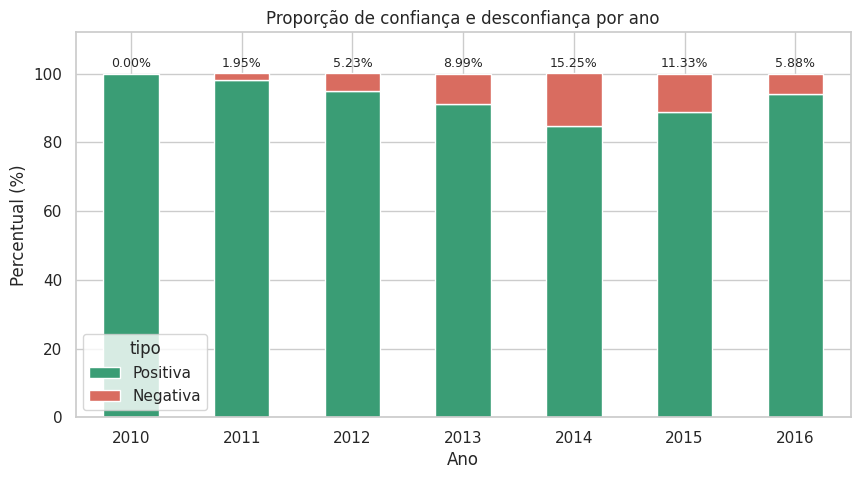

In [16]:
contagem_ano = pd.crosstab(df.ano,df.tipo).reindex(columns=["Positiva","Negativa"],fill_value=0)
percentuais = contagem_ano.div(contagem_ano.sum(axis=1),axis=0)*100
display(contagem_ano.assign(Total=contagem_ano.sum(axis=1)).join(percentuais.add_suffix(" (%)")).round(2))
ax = percentuais.plot.bar(stacked=True,color=[POSITIVA,NEGATIVA],figsize=(10,5))
ax.set(title="Proporção de confiança e desconfiança por ano", ylabel="Percentual (%)",xlabel="Ano",ylim=(0,112))
for i,v in enumerate(percentuais.Negativa): ax.text(i,102,f"{v:.2f}%",ha="center",fontsize=9)
plt.xticks(rotation=0); plt.show()

As positivas predominam em todos os anos. A parcela negativa cresce de 1,95% em 2011 para 15,25% em 2014 e depois diminui. Em 2016 há apenas 17 avaliações, portanto a proporção deve ser interpretada com cautela.

### Conectividade de entrada e avaliações negativas

,size,mean,median
grupo,,,
Sem negativas,3124,4.59,2.0
Com negativas,630,15.63,7.0


Sem avaliações recebidas: 29
Razão entre médias: 3.40471807132895


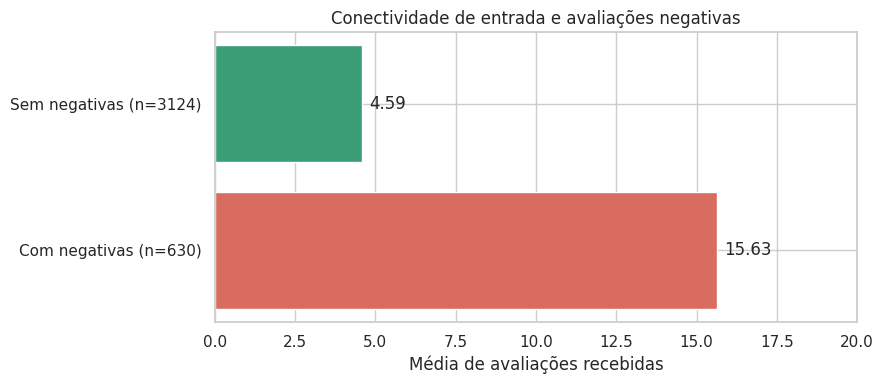

In [17]:
recebedores["grupo"] = np.where(recebedores.negativas_recebidas.gt(0),"Com negativas","Sem negativas")
grupos = recebedores.groupby("grupo").recebidas.agg(["size","mean","median"]).reindex(["Sem negativas","Com negativas"])
display(grupos.round(2))
print("Sem avaliações recebidas:", len(por_usuario)-len(recebedores))
print("Razão entre médias:", grupos.loc["Com negativas","mean"]/grupos.loc["Sem negativas","mean"])
fig,ax = plt.subplots(figsize=(9,4))
barras = ax.barh([f"{g} (n={int(r['size'])})" for g,r in grupos.iterrows()],grupos["mean"],color=[POSITIVA,NEGATIVA])
ax.bar_label(barras,fmt="%.2f",padding=5); ax.set_xlim(0,20); ax.invert_yaxis(); ax.set_xlabel("Média de avaliações recebidas"); ax.set_title("Conectividade de entrada e avaliações negativas"); plt.tight_layout(); plt.show()

Dos 3.783 usuários, 3.754 receberam avaliações. Os 3.124 sem negativas receberam em média 4,59 avaliações; os 630 com negativas, 15,63. A razão é aproximadamente 3,4. Os 29 com grau de entrada zero foram excluídos desta comparação. Usuários mais avaliados têm mais oportunidades de receber negativas; não se estabelece causalidade. Testes inferenciais usuais de grupos independentes não são adotados como prova, dada a dependência da rede e a definição dos grupos.

## 8. Síntese — storytelling e principais conclusões

1. A base contém 24.186 avaliações entre 3.783 usuários, sem ausentes ou duplicatas completas; preservamos as notas extremas válidas.
2. A confiança predomina, mas a distribuição de notas negativas concentra valores de forte desconfiança.
3. A proporção negativa aumenta até 2014 e depois diminui; o volume anual deve ser considerado na interpretação.
4. Usuários com negativas apresentam média de avaliações recebidas cerca de 3,4 vezes maior, sem evidência causal.
5. Os resultados temporais e estruturais contextualizam a pesquisa sobre caminhos e ciclos negativos; não demonstram diretamente a formação desses ciclos. Essa investigação pertence aos experimentos de grafos do projeto.

## Declaração de uso de IA
Ferramenta: ChatGPT (OpenAI). Aplicação: Organização do código e visualizações dos resultados do Bitcoin Alpha.